*   Name : Molemi Molokoane
*   Email : iimillicent02@gmail.com

In [ ]:
from google.colab import drive
drive.mount('/content/drive',  force_remount=True)

# Week 5 Assignment: Evaluating & Improving Models


## 1. Dataset, Features and Target
- **Dataset:** the Iris dataset from Scikit-learn: 150 flowers, 50 from each of three species, with no missing values.
- **Features (X):** sepal length, sepal width, petal length and petal width (all in cm).
- **Target (y):** the species: *setosa*, *versicolor* or *virginica*.
- **Task type:** **multi-class classification**, because the target is a category.

Unlike the class example (setosa vs. not setosa, which both models solve perfectly), I keep all three species. Separating *versicolor* from *virginica* is harder, so the comparison between models is more meaningful. For precision, recall and F1 I use **macro averaging**: the score is computed per species and then averaged, so each species counts equally.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             ConfusionMatrixDisplay, classification_report)

iris = load_iris(as_frame=True)
X = iris.data
y = iris.target.map(dict(enumerate(iris.target_names)))

print("Shape:", X.shape)
print("Missing values:", X.isnull().sum().sum())
print(y.value_counts())
X.head()

Shape: (150, 4)
Missing values: 0
target
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


## 2. Train/Test Split
The same split as in my Week 4 (Session 8) model: 80% training, 20% held-out test, stratified by species. The test set is only used for the final comparison, never for choosing settings.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Training rows:", len(X_train))
print("Testing rows: ", len(X_test))

Training rows: 120
Testing rows:  30


## 3. Train Two Models
1. **Logistic Regression** — my Week 4 (Session 8) model. I put it in a pipeline with `StandardScaler` so that scaling is learned from the training data only (no data leakage).
2. **Decision Tree** — the second model, trained on exactly the same training data. I start with `max_depth=3` and tune it later.

In [3]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42)),
    "Decision Tree": DecisionTreeClassifier(max_depth=3, random_state=42),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "trained")

Logistic Regression trained
Decision Tree trained


## 4. Evaluate Both Models on the Same Held-out Test Set

In [4]:
def evaluate(model, X, y):
    pred = model.predict(X)
    return {
        "Accuracy": accuracy_score(y, pred),
        "Precision (macro)": precision_score(y, pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y, pred, average="macro", zero_division=0),
        "F1 (macro)": f1_score(y, pred, average="macro", zero_division=0),
    }

comparison = pd.DataFrame({name: evaluate(m, X_test, y_test) for name, m in models.items()}).T
comparison.round(3)

,Accuracy,Precision (macro),Recall (macro),F1 (macro)
Logistic Regression,0.933,0.933,0.933,0.933
Decision Tree,0.967,0.970,0.967,0.967


In [5]:
for name, model in models.items():
    print(f"===== {name} =====")
    print(classification_report(y_test, model.predict(X_test), zero_division=0))

===== Logistic Regression =====
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

===== Decision Tree =====
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



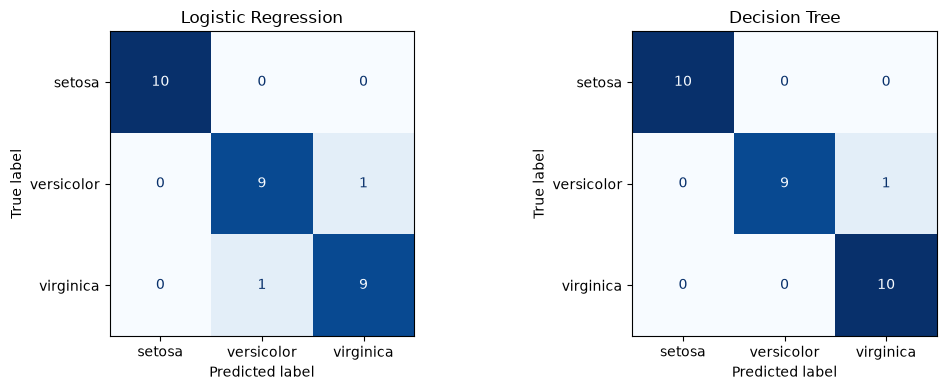

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

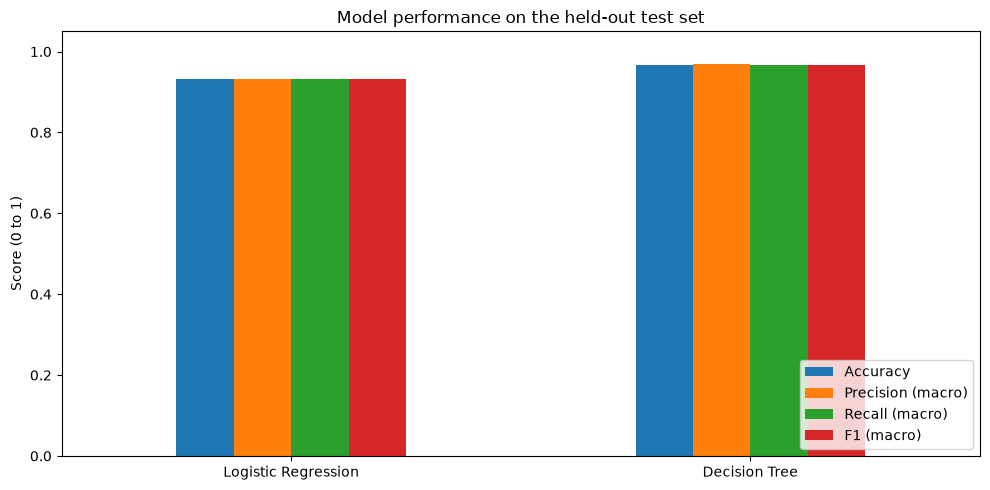

In [7]:
comparison.plot(kind="bar", figsize=(10, 5), ylim=(0, 1.05), rot=0)
plt.title("Model performance on the held-out test set")
plt.ylabel("Score (0 to 1)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

**What the test set shows:** both models classify every *setosa* correctly. The few mistakes they make are between *versicolor* and *virginica*, the two species whose measurements overlap. With only 30 test flowers, one mistake moves accuracy by about 3.3 percentage points, so a single split is not enough to pick a winner. That is why I use cross-validation next.

## 5. Cross-Validation on the Training Data
5-fold stratified cross-validation on the **training data only**. Each fold acts as the validation set once, and I report the mean and standard deviation of the macro F1-score.

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_rows = []
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="f1_macro")
    print(f"{name}: fold F1 = {scores.round(3)}")
    cv_rows.append({"Model": name, "Mean CV F1": scores.mean(), "CV Std Dev": scores.std()})

cv_table = pd.DataFrame(cv_rows).set_index("Model")
cv_table.round(3)

Logistic Regression: fold F1 = [0.958 1.    0.958 0.958 0.915]
Decision Tree: fold F1 = [0.958 1.    0.958 0.958 0.915]


,Mean CV F1,CV Std Dev
Model,,
Logistic Regression,0.958,0.027
Decision Tree,0.958,0.027


## 6. Hyperparameter Tuning with GridSearchCV
I tune the Decision Tree's `max_depth` (how many levels of questions it may ask) and `min_samples_leaf` (the minimum number of flowers in a final leaf). Both control how complex the tree can become, and therefore its risk of overfitting. GridSearchCV tries every combination with the same 5-fold cross-validation on the training data and keeps the best average macro F1.

In [9]:
param_grid = {
    "max_depth": [1, 2, 3, 4, 5, None],
    "min_samples_leaf": [1, 2, 4, 8],
}

search = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
)
search.fit(X_train, y_train)

print("Best settings:", search.best_params_)
print("Best cross-validation F1:", round(search.best_score_, 3))

Best settings: {'max_depth': 3, 'min_samples_leaf': 1}
Best cross-validation F1: 0.958


In [10]:
# Mean CV F1 for each combination
grid = pd.DataFrame(search.cv_results_)
grid["max_depth"] = grid["param_max_depth"].apply(lambda v: "None" if v is None or pd.isna(v) else str(int(v)))
grid.pivot_table(index="max_depth", columns="param_min_samples_leaf", values="mean_test_score").round(3)

param_min_samples_leaf,1,2,4,8
max_depth,,,,
1,0.556,0.556,0.556,0.556
2,0.941,0.941,0.941,0.941
3,0.958,0.958,0.941,0.941
4,0.941,0.958,0.941,0.941
5,0.950,0.958,0.941,0.941
None,0.950,0.958,0.941,0.941


In [11]:
tuned_tree = search.best_estimator_
models["Tuned Decision Tree"] = tuned_tree

before = comparison.loc["Decision Tree", "F1 (macro)"]
after = f1_score(y_test, tuned_tree.predict(X_test), average="macro")
print(f"Original Decision Tree test F1: {before:.3f}")
print(f"Tuned Decision Tree test F1:    {after:.3f}")
print(f"Change: {after - before:+.3f}")

Original Decision Tree test F1: 0.967
Tuned Decision Tree test F1:    0.967
Change: +0.000


## 7. Final Comparison

In [12]:
final = pd.DataFrame({name: evaluate(m, X_test, y_test) for name, m in models.items()}).T
final["Mean CV F1"] = [cv_table.loc["Logistic Regression", "Mean CV F1"],
                       cv_table.loc["Decision Tree", "Mean CV F1"],
                       search.best_score_]
final.round(3)

,Accuracy,Precision (macro),Recall (macro),F1 (macro),Mean CV F1
Logistic Regression,0.933,0.933,0.933,0.933,0.958
Decision Tree,0.967,0.970,0.967,0.967,0.958
Tuned Decision Tree,0.967,0.970,0.967,0.967,0.958


## 8. Conclusion

1. The model with the highest mean cross-validation F1 was **a tie**: Logistic Regression and the Decision Tree both scored **0.958** (std 0.027), with identical scores in every fold.
2. On the held-out test set the **Decision Tree** scored higher (macro F1 0.967 vs 0.933). This difference is only **one flower** out of 30: the tree misclassified one *versicolor*, while Logistic Regression mixed up one *versicolor* and one *virginica*. Both models classified every *setosa* correctly.
3. The most important metric here is **macro F1**, because the classes are balanced and every species matters equally, so I want a model that has both good precision and good recall for each species, not just for the easy *setosa* class.
4. Tuning with GridSearchCV picked `max_depth=3, min_samples_leaf=1`, the same depth I had chosen, so the tuned tree's test F1 stayed at **0.967 (change +0.000)**. The grid shows that a depth of 1 clearly underfits (CV F1 0.556), and deeper or unlimited trees do not improve the cross-validation score, which suggests that extra depth only adds a risk of overfitting.

**My choice:** the evidence is essentially a tie. Cross-validation, which uses more data than the 30-flower test set, shows no difference at all, and the test-set gap of a single flower is too small to be convincing. I would choose the **depth-3 Decision Tree**, because it matched Logistic Regression in cross-validation, was slightly better on the test set, and is easy to explain as a few simple rules about petal size. It also needs no feature scaling. However, if this were a larger or noisier dataset I would keep Logistic Regression as a strong candidate, because linear models are usually more stable than trees when the data changes slightly.